# Tata Consumer Stock Closing Price Prediction using LSTM


**Prediction flow:** Previous 60 trading days → LSTM → closing price of selected historical date.



**LSTM Architecture:**

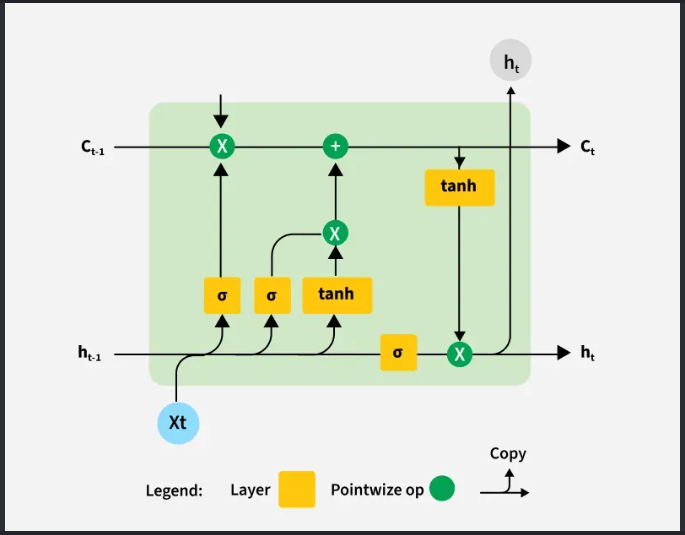

## 1. Upload dataset

In [ ]:
from google.colab import files

uploaded = files.upload()
FILE_NAME = list(uploaded.keys())[0]

print("Uploaded file:", FILE_NAME)


Saving TATACONSUM_historical_data_Daily_Full_History.csv to TATACONSUM_historical_data_Daily_Full_History.csv
Uploaded file: TATACONSUM_historical_data_Daily_Full_History.csv


## 2. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


## 3. Load and clean the actual CSV structure

In [ ]:
# The uploaded CSV has:
# Row 0 = ticker names
# Row 1 = column labels
# Row 2 onward = actual historical observations

raw_df = pd.read_csv(FILE_NAME, header=None)

print("Raw shape:", raw_df.shape)
display(raw_df.head())


Raw shape: (5843, 7)


,0,1,2,3,4,5,6
0,Date,Open,High,Low,Close,Volume,Exchange
1,2026-09-28,983.20,983.60,955.50,960.00,1307916,NSE
2,2026-09-25,988.00,989.90,979.20,983.20,885948,NSE
3,2026-09-24,989.00,992.00,983.00,986.30,1002889,NSE
4,2026-09-23,988.40,997.10,985.00,994.30,850774,NSE


In [ ]:
# Keep actual observations only
df = raw_df.iloc[2:].copy()

# Show the columns before doing anything
print("Columns before cleaning:")
print(df.columns.tolist())

# If there is an unwanted extra column, keep only the 6 required columns
df = df.iloc[:, :6].copy()

# Rename columns
df.columns = [
    "Date",
    "Close",
    "High",
    "Low",
    "Open",
    "Volume"
]

# Convert date
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

# Convert OHLCV columns to numbers
numeric_cols = [
    "Close",
    "High",
    "Low",
    "Open",
    "Volume"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Remove invalid rows
df = df.dropna(
    subset=["Date"] + numeric_cols
).copy()

# Sort from oldest to newest
df = df.sort_values(
    "Date"
).reset_index(drop=True)

print("Cleaned shape:", df.shape)

print(
    "Date range:",
    df["Date"].min().date(),
    "to",
    df["Date"].max().date()
)

display(df.head())

Columns before cleaning:
[0, 1, 2, 3, 4, 5, 6]
Cleaned shape: (5841, 6)
Date range: 2003-01-01 to 2026-09-25


,Date,Close,High,Low,Open,Volume
0,2003-01-01,17.20,17.25,17.10,17.20,407300
1,2003-01-02,17.25,17.40,16.95,17.05,1131288
2,2003-01-03,17.10,17.15,16.80,16.90,405092
3,2003-01-06,16.95,17.05,16.70,16.80,522180
4,2003-01-07,16.80,16.95,16.60,16.65,400628


## 4. Create features from the OHLCV data

In [ ]:
# Daily percentage return
df["daily_return"] = df["Close"].pct_change()

# Moving averages
df["MA_5"] = df["Close"].rolling(5).mean()
df["MA_20"] = df["Close"].rolling(20).mean()
df["MA_50"] = df["Close"].rolling(50).mean()

# 10-day volatility
df["volatility_10d"] = (
    df["daily_return"].rolling(10).std()
)

# Volume features
df["volume_MA_5"] = (
    df["Volume"].rolling(5).mean()
)

df["volume_ratio"] = (
    df["Volume"] / df["volume_MA_5"]
)

# Rolling features create NaN values at the beginning
df = df.dropna().reset_index(drop=True)

print("Rows after feature engineering:", len(df))
display(df.head())


Rows after feature engineering: 5792


,Date,Close,High,Low,Open,Volume,daily_return,MA_5,MA_20,MA_50,volatility_10d,volume_MA_5,volume_ratio
0,2003-03-12,17.30,17.4,17.0,17.10,536081,0.020649,17.29,17.150,16.788,0.030635,1241029.6,0.431965
1,2003-03-13,17.30,17.4,17.0,17.10,296995,0.000000,17.25,17.235,16.790,0.030635,1081582.0,0.274593
2,2003-03-17,17.15,17.3,16.7,17.20,971304,-0.008671,17.30,17.285,16.788,0.030331,749885.6,1.295270
3,2003-03-19,17.20,17.5,17.0,17.45,552249,0.002915,17.18,17.325,16.790,0.030386,628390.0,0.878832
4,2003-03-20,17.40,17.6,17.2,17.55,586166,0.011628,17.27,17.395,16.799,0.030343,588559.0,0.995934


## 5. Select input features and target

In [ ]:
feature_cols = [
    "Close",
    "High",
    "Low",
    "Open",
    "Volume",
    "daily_return",
    "MA_5",
    "MA_20",
    "MA_50",
    "volatility_10d",
    "volume_MA_5",
    "volume_ratio"
]

target_col = "Close"

print("Input features:")
for col in feature_cols:
    print("-", col)

print("\nTarget:", target_col)


Input features:
- Close
- High
- Low
- Open
- Volume
- daily_return
- MA_5
- MA_20
- MA_50
- volatility_10d
- volume_MA_5
- volume_ratio

Target: Close


## 6. View historical closing price

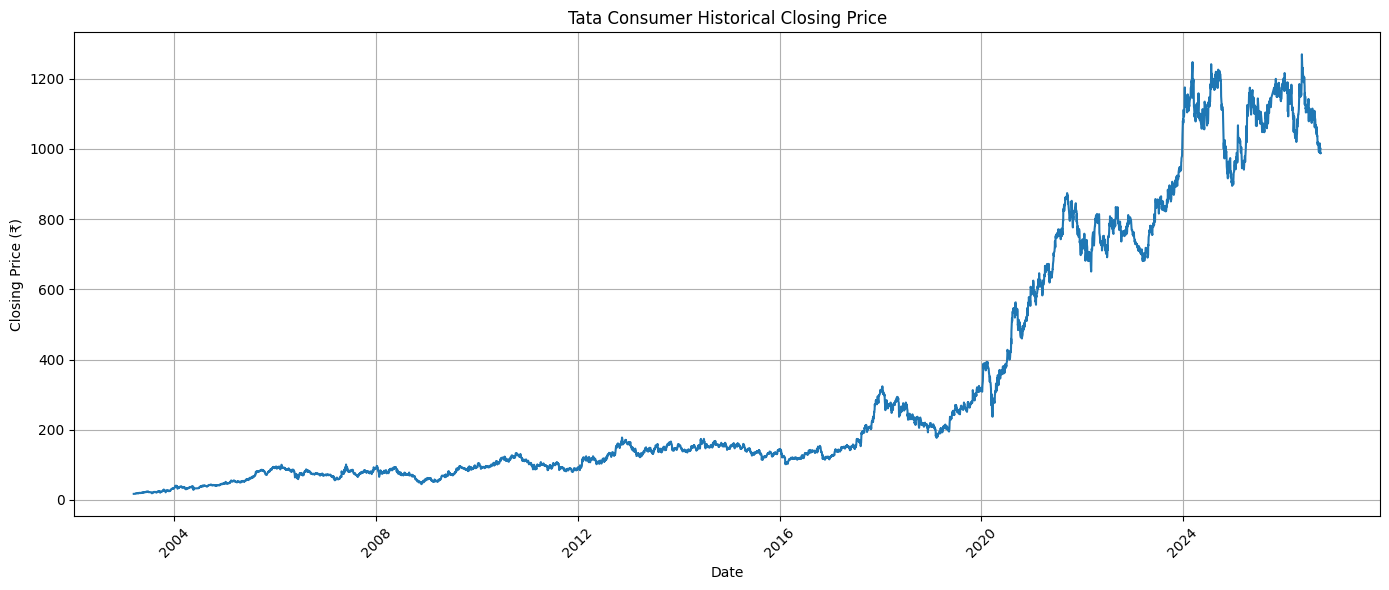

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"]
)

plt.xlabel("Date")
plt.ylabel("Closing Price (₹)")
plt.title("Tata Consumer Historical Closing Price")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 7. Chronological train/test split

In [ ]:
# Never randomly shuffle stock time-series data
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining:")
print(train_df["Date"].min().date(), "to", train_df["Date"].max().date())

print("\nTesting:")
print(test_df["Date"].min().date(), "to", test_df["Date"].max().date())


Training rows: 4633
Testing rows: 1159

Training:
2003-03-12 to 2022-01-05

Testing:
2022-01-06 to 2026-09-25


## 8. Scale data without test-data leakage

In [ ]:
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

# Fit scalers ONLY on training data
x_scaler.fit(train_df[feature_cols])
y_scaler.fit(train_df[[target_col]])

# Transform all rows using those training-fitted scalers
X_all_scaled = x_scaler.transform(df[feature_cols])
y_all_scaled = y_scaler.transform(df[[target_col]])

print("Scaling completed.")


Scaling completed.


## 9. Create 60-day LSTM sequences

In [ ]:
sequence_length = 60

X = []
y = []
target_indices = []

for i in range(sequence_length, len(df)):

    # Previous 60 trading days
    X.append(
        X_all_scaled[
            i-sequence_length:i
        ]
    )

    # Close of the target date
    y.append(
        y_all_scaled[i]
    )

    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (5732, 60, 12)
y shape: (5732, 1)


### Meaning of one sequence

For a selected target date:

**60 previous trading days → LSTM → target date closing price**


## 10. Split sequences into train and test

In [ ]:
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

test_indices = target_indices[test_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)


X_train: (4573, 60, 12)
y_train: (4573, 1)
X_test : (1159, 60, 12)
y_test : (1159, 1)


## 11. Build LSTM model

In [ ]:
model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    ),

    Dropout(0.20),

    LSTM(
        32,
        return_sequences=False
    ),

    Dropout(0.20),

    Dense(
        16,
        activation="relu"
    ),

    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,673 (127.63 KB)

 Trainable params: 32,673 (127.63 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Train model

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step - loss: 0.0024 - val_loss: 0.0249
Epoch 2/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - loss: 0.0010 - val_loss: 0.0269
Epoch 3/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - loss: 7.6540e-04 - val_loss: 0.0088
Epoch 4/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - loss: 8.0715e-04 - val_loss: 0.0422
Epoch 5/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - loss: 6.2291e-04 - val_loss: 0.0275
Epoch 6/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - loss: 5.7813e-04 - val_loss: 0.0243
Epoch 7/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - loss: 5.3987e-04 - val_loss: 0.0230
Epoch 8/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 12s 65ms/step - loss: 5.2940e-04 - val_loss: 0.0083
Epoch 9/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - loss: 4.6927e-04 - val_loss: 0.0470
Epoch 10/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - loss: 4.2387e-04 - val_loss: 0.0235
Epoch 11/30
143/143 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - loss: 4.3190e-04 - val_loss: 0.0382


## 13. Training/validation loss

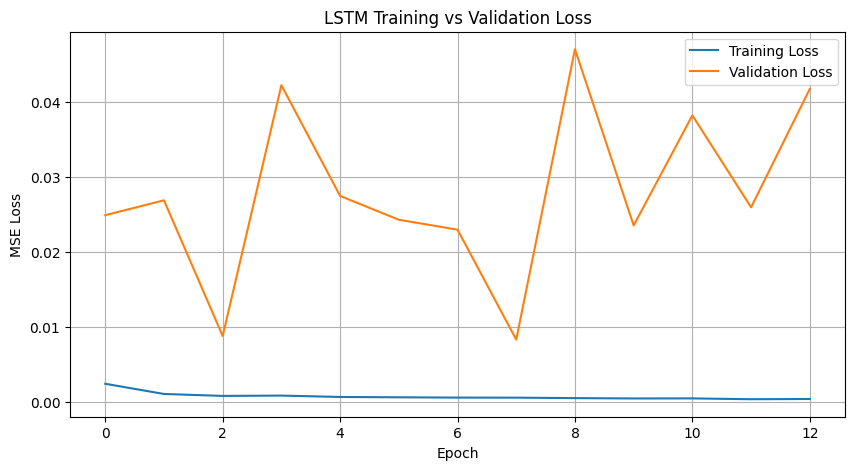

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


## 14. Predict test data

In [ ]:
# ACTUAL MODEL PREDICTION
y_pred_scaled = model.predict(
    X_test,
    verbose=0
)

# Convert scaled values back to rupees
y_pred = y_scaler.inverse_transform(
    y_pred_scaled
)

y_actual = y_scaler.inverse_transform(
    y_test
)

print("Prediction completed.")
print("\nFirst 5 predicted prices:")
print(np.round(y_pred[:5].flatten(), 2))

print("\nFirst 5 actual prices:")
print(np.round(y_actual[:5].flatten(), 2))


Prediction completed.

First 5 predicted prices:
[722.06 722.3  722.57 723.74 724.76]

First 5 actual prices:
[724.   716.55 731.35 727.4  733.9 ]


## 15. Model evaluation

In [ ]:
mae = mean_absolute_error(
    y_actual,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_actual,
        y_pred
    )
)

print("================================")
print("MODEL EVALUATION")
print("================================")
print("MAE  : ₹", round(mae, 2))
print("RMSE : ₹", round(rmse, 2))


MODEL EVALUATION
MAE  : ₹ 62.6
RMSE : ₹ 77.96


## 16. Actual vs predicted test prices

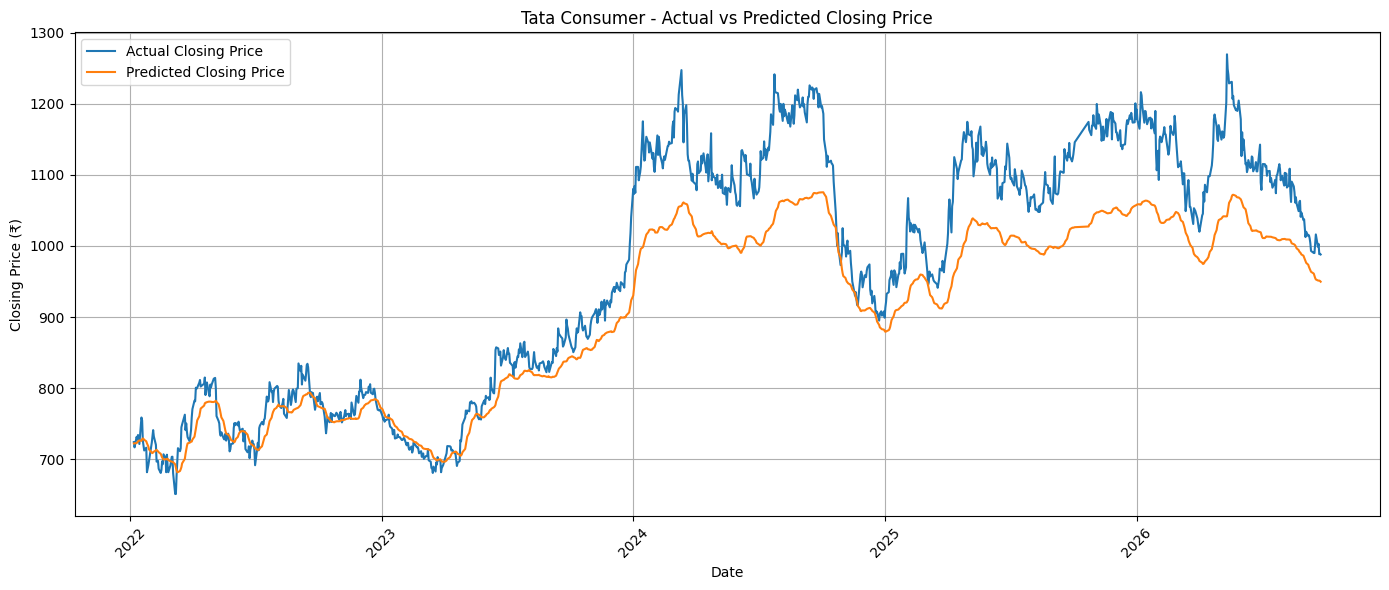

In [ ]:
test_dates = df.loc[
    test_indices,
    "Date"
]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_actual.flatten(),
    label="Actual Closing Price"
)

plt.plot(
    test_dates,
    y_pred.flatten(),
    label="Predicted Closing Price"
)

plt.xlabel("Date")
plt.ylabel("Closing Price (₹)")
plt.title("Tata Consumer - Actual vs Predicted Closing Price")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 17. USER DATE INPUT - MAIN DEMO

Enter a date that exists in the historical dataset.

The model will:

1. Find the selected date.
2. Take the previous 60 trading days.
3. Scale those days.
4. Send them to the trained LSTM.
5. Predict the closing price.
6. Convert the prediction back to ₹.
7. Compare it with the actual historical closing price.


In [ ]:
# ==========================================
# USER INPUT
# ==========================================

user_input = input(
    "Enter the date (YYYY-MM-DD): "
).strip()

try:
    user_date = pd.to_datetime(
        user_input,
        format="%Y-%m-%d"
    )
except ValueError:
    print("\nInvalid date format.")
    print("Use YYYY-MM-DD, for example 2024-06-20.")
    raise SystemExit


# ==========================================
# FIND TARGET DATE
# ==========================================

matches = df.index[
    df["Date"] == user_date
].tolist()

if len(matches) == 0:

    print("\nDate not found in the dataset.")
    print(
        "Please enter a trading date contained in the CSV."
    )

    print(
        "\nAvailable range:",
        df["Date"].min().strftime("%Y-%m-%d"),
        "to",
        df["Date"].max().strftime("%Y-%m-%d")
    )

else:

    target_index = matches[0]

    # Need 60 previous trading days
    if target_index < sequence_length:

        print("\nNot enough previous data.")
        print(
            f"The model needs {sequence_length} "
            "previous trading days."
        )

    else:

        # ------------------------------------------
        # 1. Previous 60 trading days
        # ------------------------------------------

        input_data = df.loc[
            target_index-sequence_length:
            target_index-1,
            feature_cols
        ].values


        # ------------------------------------------
        # 2. Scale using training scaler
        # ------------------------------------------

        input_scaled = x_scaler.transform(
            input_data
        )


        # ------------------------------------------
        # 3. LSTM input shape
        # ------------------------------------------

        model_input = input_scaled.reshape(
            1,
            sequence_length,
            len(feature_cols)
        )


        # ------------------------------------------
        # 4. PREDICTION HAPPENS HERE
        # ------------------------------------------

        predicted_scaled = model.predict(
            model_input,
            verbose=0
        )


        # ------------------------------------------
        # 5. Convert back to ₹
        # ------------------------------------------

        predicted_price = y_scaler.inverse_transform(
            predicted_scaled
        )[0][0]


        # ------------------------------------------
        # 6. Actual historical close
        # ------------------------------------------

        actual_price = df.loc[
            target_index,
            "Close"
        ]


        # ------------------------------------------
        # 7. Error
        # ------------------------------------------

        absolute_error = abs(
            actual_price - predicted_price
        )

        percentage_error = (
            absolute_error / actual_price
        ) * 100


        # ------------------------------------------
        # 8. DISPLAY
        # ------------------------------------------

        print("\n")
        print("=" * 55)
        print("       TATA CONSUMER STOCK PREDICTION")
        print("=" * 55)

        print(
            "Selected Date           :",
            user_date.strftime("%Y-%m-%d")
        )

        print(
            "Predicted Closing Price : ₹",
            round(predicted_price, 2)
        )

        print(
            "Actual Closing Price    : ₹",
            round(actual_price, 2)
        )

        print(
            "Absolute Error          : ₹",
            round(absolute_error, 2)
        )

        print(
            "Percentage Error        :",
            round(percentage_error, 2),
            "%"
        )

        print("=" * 55)


Enter the date (YYYY-MM-DD): 2006-08-08


       TATA CONSUMER STOCK PREDICTION
Selected Date           : 2006-08-08
Predicted Closing Price : ₹ 83.11
Actual Closing Price    : ₹ 83.15
Absolute Error          : ₹ 0.04
Percentage Error        : 0.04 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


## 18. Visualize the selected-date prediction

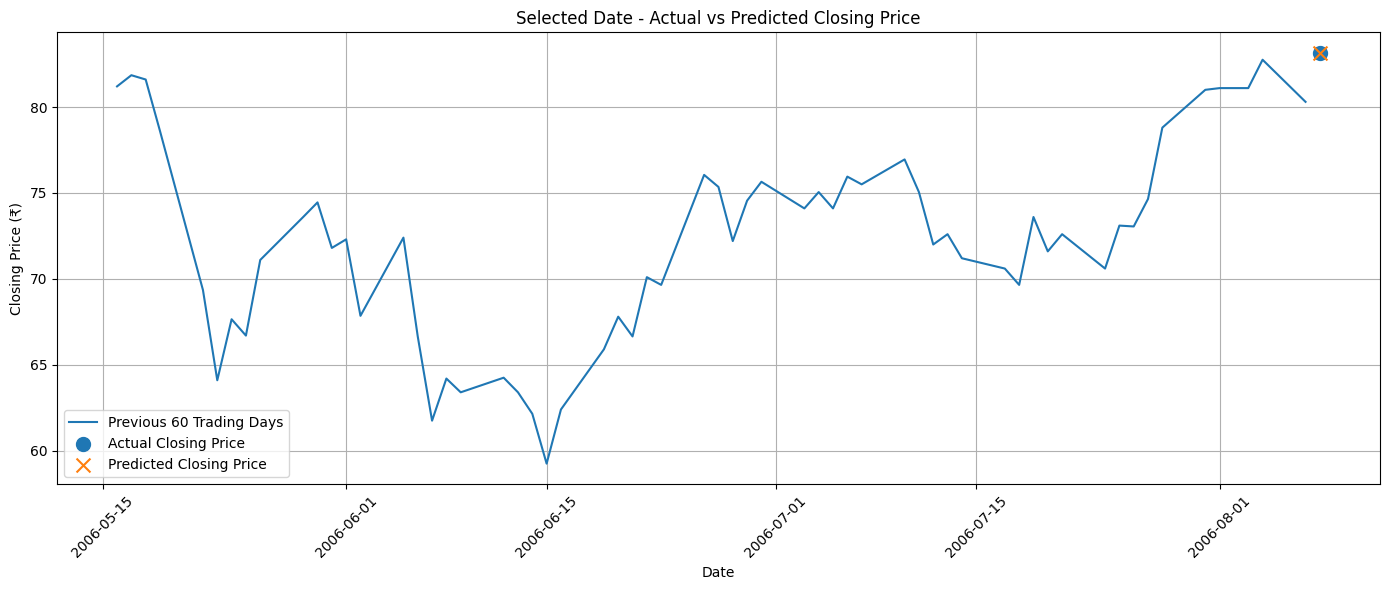

In [ ]:
if (
    len(matches) > 0
    and target_index >= sequence_length
):

    previous_dates = df.loc[
        target_index-sequence_length:
        target_index-1,
        "Date"
    ]

    previous_close = df.loc[
        target_index-sequence_length:
        target_index-1,
        "Close"
    ]

    plt.figure(figsize=(14, 6))

    plt.plot(
        previous_dates,
        previous_close,
        label="Previous 60 Trading Days"
    )

    plt.scatter(
        user_date,
        actual_price,
        s=100,
        marker="o",
        label="Actual Closing Price"
    )

    plt.scatter(
        user_date,
        predicted_price,
        s=100,
        marker="x",
        label="Predicted Closing Price"
    )

    plt.xlabel("Date")
    plt.ylabel("Closing Price (₹)")
    plt.title("Selected Date - Actual vs Predicted Closing Price")
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
